<a href="https://colab.research.google.com/github/AidaAm005/NHANES-Tobacco-Biomarkers/blob/phase-2/notebooks/phase2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import sys
from google.colab import drive

drive.mount('/content/drive')

PROJECT_ROOT = '/content/drive/MyDrive/NHANES-Tobacco-Biomarkers'
os.chdir(PROJECT_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print("مسیر کاری فعلی:", os.getcwd())
print("فایل‌های موجود در src:", sorted(os.listdir('src')))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
مسیر کاری فعلی: /content/drive/MyDrive/NHANES-Tobacco-Biomarkers
فایل‌های موجود در src: ['.ipynb_checkpoints', '__init__.py', '__pycache__', 'bayes_and_nhanes_probs.py', 'data_cleaner.py', 'data_loader.py', 'descriptive_stats.py', 'distributions_analysis.py', 'probability_events.py', 'survey_design.py']


In [2]:
from src.data_loader import fetch_raw_datasets, merge_datasets
from src.data_cleaner import fix_sas_zeros, audit_and_clean_special_codes
from src.survey_design import define_analytic_population

raw_datasets, _ = fetch_raw_datasets()
df_merged_raw, _ = merge_datasets(raw_datasets)
df_step1, _ = fix_sas_zeros(df_merged_raw)
df_cleaned, _ = audit_and_clean_special_codes(df_step1)
df_analytic, df_flow = define_analytic_population(df_cleaned)

print(f"حجم جمعیت تحلیلی نهایی (df_analytic): {len(df_analytic)} نفر")
assert len(df_analytic) == 4655, "خطا: حجم جمعیت تحلیلی با فاز اول همخوانی ندارد!"
print("تایید شد: جمعیت تحلیلی دقیقاً منطبق بر فاز اول است.")

حجم جمعیت تحلیلی نهایی (df_analytic): 4655 نفر
تایید شد: جمعیت تحلیلی دقیقاً منطبق بر فاز اول است.


In [3]:
import importlib
import src.probability_events as pe
importlib.reload(pe)

df_p2 = pe.add_phase2_events_and_rvs(df_analytic)
df_ev_summary, df_rv_summary = pe.verify_task1_analytic_summary(df_p2)

print("=== جدول ۱-الف: فراوانی و احتمال حاشیه‌ای رویدادهای دودویی در جمعیت تحلیلی (N=4,655) ===")
display(df_ev_summary)

print("\n=== جدول ۱-ب: بازه دقیق (کمینه، چارک‌ها و بیشینه) متغیرهای تصادفی روی جمعیت تحلیلی ===")
display(df_rv_summary)

=== جدول ۱-الف: فراوانی و احتمال حاشیه‌ای رویدادهای دودویی در جمعیت تحلیلی (N=4,655) ===


,Event,Count (n),Complement_Count,Total_N,Empirical_Prob,Percent (%)
0,A: Combustible Smoker (G3 U G4),775,3880,4655,0.1665,16.65
1,B: High Blood Cadmium (LBXBCD >= 0.5 ug/L),971,3684,4655,0.2086,20.86
2,C: Active Nicotine (LBXCOT >= 10.0 ng/mL),912,3743,4655,0.1959,19.59
3,M: Male Participants (RIAGENDR = 1),2094,2561,4655,0.4498,44.98



=== جدول ۱-ب: بازه دقیق (کمینه، چارک‌ها و بیشینه) متغیرهای تصادفی روی جمعیت تحلیلی ===


,Variable,Description,Valid_N,Min,Q1,Median,Q3,Max
0,LBXBCD,W: Blood Cadmium (ug/L),4655,0.046,0.170,0.262,0.442,7.684
1,Log10_LBXBCD,Y1: Log10 Blood Cadmium,4655,-1.337,-0.770,-0.582,-0.355,0.886
2,LBXCOT,Raw Serum Cotinine (ng/mL),4655,0.007,0.007,0.014,0.232,889.000
3,Log10_LBXCOT,Y2: Log10 Serum Cotinine,4655,-2.155,-2.155,-1.854,-0.635,2.949
4,LBXHGB,Y3: Hemoglobin (g/dL),4638,6.600,13.000,13.900,14.900,18.600
5,RIDAGEYR,Age (Years),4655,20.000,40.000,58.000,68.000,80.000


In [4]:
# جفت اصلی ۱: مصرف سیگار احتراقی (A) و کادمیوم بالای خون (B)
ct_ab_counts, ct_ab_probs = pe.compute_marginal_and_joint_tables(
    df_p2, "Event_A_Label", "Event_B_Label"
)
print("=== جدول ۲-۱ (فراوانی): جدول توافقی رویداد A (سیگار احتراقی) و رویداد B (کادمیوم >= 0.5) ===")
display(ct_ab_counts)

print("\n=== جدول ۲-۲ (احتمال مشترک و حاشیه‌ای): P(A), P(B), P(A ∩ B) ===")
display(ct_ab_probs)

# جفت مکمل ۲: مصرف سیگار احتراقی (A) و مواجهه فعال با نیکوتین (C)
ct_ac_counts, ct_ac_probs = pe.compute_marginal_and_joint_tables(
    df_p2, "Event_A_Label", "Event_C_Label"
)
print("\n=== جدول ۲-۳ (احتمال مشترک و حاشیه‌ای): رویداد A و رویداد C (کوتینین >= 10) ===")
display(ct_ac_probs)

=== جدول ۲-۱ (فراوانی): جدول توافقی رویداد A (سیگار احتراقی) و رویداد B (کادمیوم >= 0.5) ===


Event_B_Label,B: High Cadmium (>=0.5),B^c: Low Cadmium (<0.5),Total (Marginal)
Event_A_Label,,,
A: Combustible Smoker,536,239,775
A^c: Non-Combustible,435,3445,3880
Total (Marginal),971,3684,4655



=== جدول ۲-۲ (احتمال مشترک و حاشیه‌ای): P(A), P(B), P(A ∩ B) ===


Event_B_Label,B: High Cadmium (>=0.5),B^c: Low Cadmium (<0.5),Total (Marginal)
Event_A_Label,,,
A: Combustible Smoker,0.1151,0.0513,0.1665
A^c: Non-Combustible,0.0934,0.7401,0.8335
Total (Marginal),0.2086,0.7914,1.0000



=== جدول ۲-۳ (احتمال مشترک و حاشیه‌ای): رویداد A و رویداد C (کوتینین >= 10) ===


Event_C_Label,C: Active Nicotine (>=10),C^c: No Active Nicotine (<10),Total (Marginal)
Event_A_Label,,,
A: Combustible Smoker,0.1538,0.0127,0.1665
A^c: Non-Combustible,0.0421,0.7914,0.8335
Total (Marginal),0.1959,0.8041,1.0000


=== جدول ۳-۱: احتمال شرطی کادمیوم بالا (B) و نیکوتین فعال (C) به شرط رویداد A و متمم آن ===


,Conditioning_Event,Group_N,Count_B (High Cd),P(B | Condition),Shift_vs_P(B),Ratio_to_P(B),Count_C (Active Cot),P(C | Condition),Shift_vs_P(C)
0,A: Combustible Smoker,775,536,0.6916,0.4830,3.32,716,0.9239,0.7280
1,A^c: Non-Combustible,3880,435,0.1121,-0.0965,0.54,196,0.0505,-0.1454



=== جدول ۳-۲: احتمال شرطی B و C به تفکیک هر چهار گروه افراز (G1 تا G4) ===


,Smoking_Group,Group_N,Count_B (High Cd),P(B | Group),P(B | Group) %,Count_C (Active Cot),P(C | Group),P(C | Group) %
0,1. Non-Smoker,3734,421,0.1127,11.27,82,0.0220,2.20
1,2. Exclusive Vape,146,14,0.0959,9.59,114,0.7808,78.08
2,3. Exclusive Cigarette,672,488,0.7262,72.62,620,0.9226,92.26
3,4. Dual User,103,48,0.4660,46.60,96,0.9320,93.20


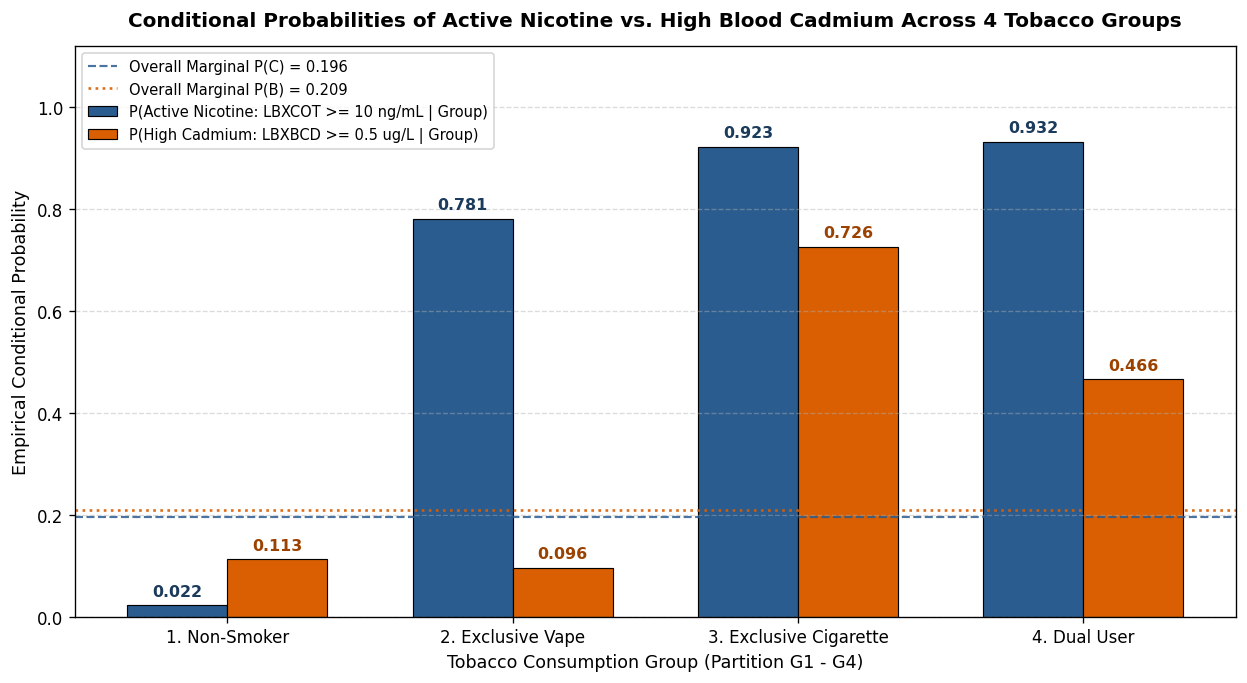

نمودار در مسیر زیر ذخیره شد: figures/p2_fig1_conditional_probs.png


In [5]:
df_cond_binary, df_cond_4groups = pe.compute_conditional_probabilities(df_p2)

print("=== جدول ۳-۱: احتمال شرطی کادمیوم بالا (B) و نیکوتین فعال (C) به شرط رویداد A و متمم آن ===")
display(df_cond_binary)

print("\n=== جدول ۳-۲: احتمال شرطی B و C به تفکیک هر چهار گروه افراز (G1 تا G4) ===")
display(df_cond_4groups)

fig_path = pe.plot_conditional_probabilities(df_p2, df_cond_4groups, output_dir="figures")
print("نمودار در مسیر زیر ذخیره شد:", fig_path)

In [6]:
import pandas as pd

indep_results = [
    pe.evaluate_independence(
        df_p2, "Event_A_Combustible", "Event_B_HighCd",
        "Pair 1: Combustible Smoker (A) & High Cadmium (B)"
    ),
    pe.evaluate_independence(
        df_p2, "Event_A_Combustible", "Event_C_ActiveCot",
        "Pair 2: Combustible Smoker (A) & Active Nicotine (C)"
    ),
    pe.evaluate_independence(
        df_p2, "Event_Male", "Event_B_HighCd",
        "Pair 3 (Contrast): Male Gender (M) & High Cadmium (B)"
    )
]

df_indep_audit = pd.DataFrame(indep_results)
print("=== جدول ۴-۱: بررسی استدلالی استقلال رویدادها (مقایسه P(E1 ∩ E2) با P(E1)*P(E2)) ===")
display(df_indep_audit)

=== جدول ۴-۱: بررسی استدلالی استقلال رویدادها (مقایسه P(E1 ∩ E2) با P(E1)*P(E2)) ===


,Event_Pair,N_Total,P(E1),P(E2),Observed_P(E1 n E2),Expected_Under_Indep_P(E1)*P(E2),Joint_Diff (Obs - Exp),Joint_Ratio (Obs / Exp),P(E2 | E1),P(E2 | E1^c),Cond_Shift [P(E2|E1) - P(E2)]
0,Pair 1: Combustible Smoker (A) & High Cadmium (B),4655,0.1665,0.2086,0.1151,0.0347,0.0804,3.32,0.6916,0.1121,0.4830
1,Pair 2: Combustible Smoker (A) & Active Nicoti...,4655,0.1665,0.1959,0.1538,0.0326,0.1212,4.72,0.9239,0.0505,0.7280
2,Pair 3 (Contrast): Male Gender (M) & High Cadm...,4655,0.4498,0.2086,0.0782,0.0938,-0.0156,0.83,0.1738,0.2370,-0.0348


=== جدول ۵-۱: مشخصات مدل Binomial(n=30, p) و مقایسه واریانس با مدل فوق‌هندسی ===


,Population_Regime,Subpop_Size (N),Sampling_Frac (n/N %),p_hat = P(B),E[K_30] = np,Var_Binom,Var_Hypergeom,SD_Binom,P(K=0),P(K<=5),P(K>=10)
0,Overall Analytic Population (Omega),4655,0.64,0.2086,6.26,4.95,4.92,2.23,0.0009,0.3823,0.0777
1,1. Non-Smoker (G1 - Homogeneous),3734,0.80,0.1127,3.38,3.00,2.98,1.73,0.0276,0.8852,0.0012
2,2. Exclusive Vape (G2 - Small Subgroup),146,20.55,0.0959,2.88,2.60,2.08,1.61,0.0486,0.9379,0.0003
3,3. Exclusive Cigarette (G3 - Homogeneous),672,4.46,0.7262,21.79,5.97,5.71,2.44,0.0000,0.0000,1.0000
4,4. Dual User (G4 - Small Subgroup),103,29.13,0.4660,13.98,7.47,5.34,2.73,0.0000,0.0006,0.9511



=== جدول ۵-۲: ممیزی ناهمگنی احتمال P(B) در میان ۳۰ خوشه جغرافیایی (PSU) ===


,Num_PSUs,Overall_P(B),Min_P(B)_Across_PSUs,Max_P(B)_Across_PSUs,Range_Across_PSUs,SD_of_P(B)_Across_PSUs
0,30,0.2086,0.1382,0.3333,0.1951,0.0516


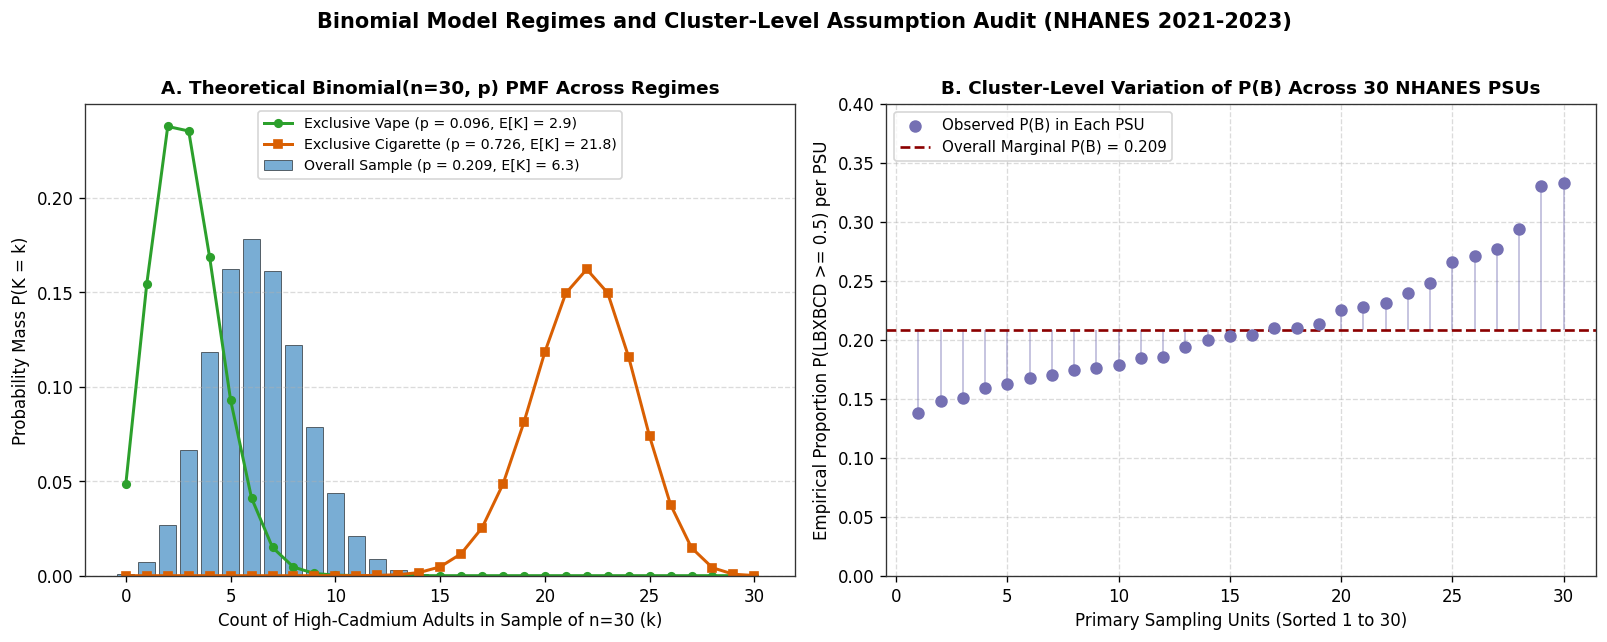

نمودار تسک ۵ ذخیره شد: figures/p2_fig2_binomial_model.png


In [7]:
import importlib
import src.distributions_analysis as da
importlib.reload(da)

df_binom_summary, df_psu_summary, df_psu_stats = da.analyze_binomial_model_and_assumptions(
    df_p2, n_trials=30
)

print("=== جدول ۵-۱: مشخصات مدل Binomial(n=30, p) و مقایسه واریانس با مدل فوق‌هندسی ===")
display(df_binom_summary)

print("\n=== جدول ۵-۲: ممیزی ناهمگنی احتمال P(B) در میان ۳۰ خوشه جغرافیایی (PSU) ===")
display(df_psu_summary)

fig2_path = da.plot_binomial_model_and_clusters(df_p2, df_psu_stats, n_trials=30, output_dir="figures")
print("نمودار تسک ۵ ذخیره شد:", fig2_path)

=== جدول ۶-۱: ارزیابی شکل توزیع، قانون تجربی 68-95-99.7% و احتمال منفی ناممکن ===


,Variable,N,Mean,Median,SD,Skewness,Excess_Kurtosis,Within_1SD (%) [Ref: 68.27],Within_2SD (%) [Ref: 95.45],Within_3SD (%) [Ref: 99.73],Normal_P(X<0) (%)
0,W: Raw Blood Cadmium (ug/L),4655,0.4076,0.2620,0.5005,5.251,42.570,92.03,96.24,98.13,20.77
1,Y1: Log10 Blood Cadmium [log10(ug/L)],4655,-0.5424,-0.5817,0.3325,0.670,0.717,70.91,95.15,99.25,NaN



=== جدول ۶-۲: مقایسه صدک‌های تجربی با صدک‌های نظری توزیع نرمال ===


,Variable,Percentile,Empirical_Quantile,Normal_Theoretical_Quantile,Diff (Emp - Theo)
0,LBXBCD,P5,0.0960,-0.4156,0.5116
1,LBXBCD,P25,0.1700,0.0701,0.0999
2,LBXBCD,P50,0.2620,0.4076,-0.1456
3,LBXBCD,P75,0.4420,0.7452,-0.3032
4,LBXBCD,P95,1.2203,1.2309,-0.0106
5,Log10_LBXBCD,P5,-1.0177,-1.0892,0.0715
6,Log10_LBXBCD,P25,-0.7696,-0.7666,-0.0029
7,Log10_LBXBCD,P50,-0.5817,-0.5424,-0.0393
8,Log10_LBXBCD,P75,-0.3546,-0.3181,-0.0364
9,Log10_LBXBCD,P95,0.0865,0.0045,0.0820


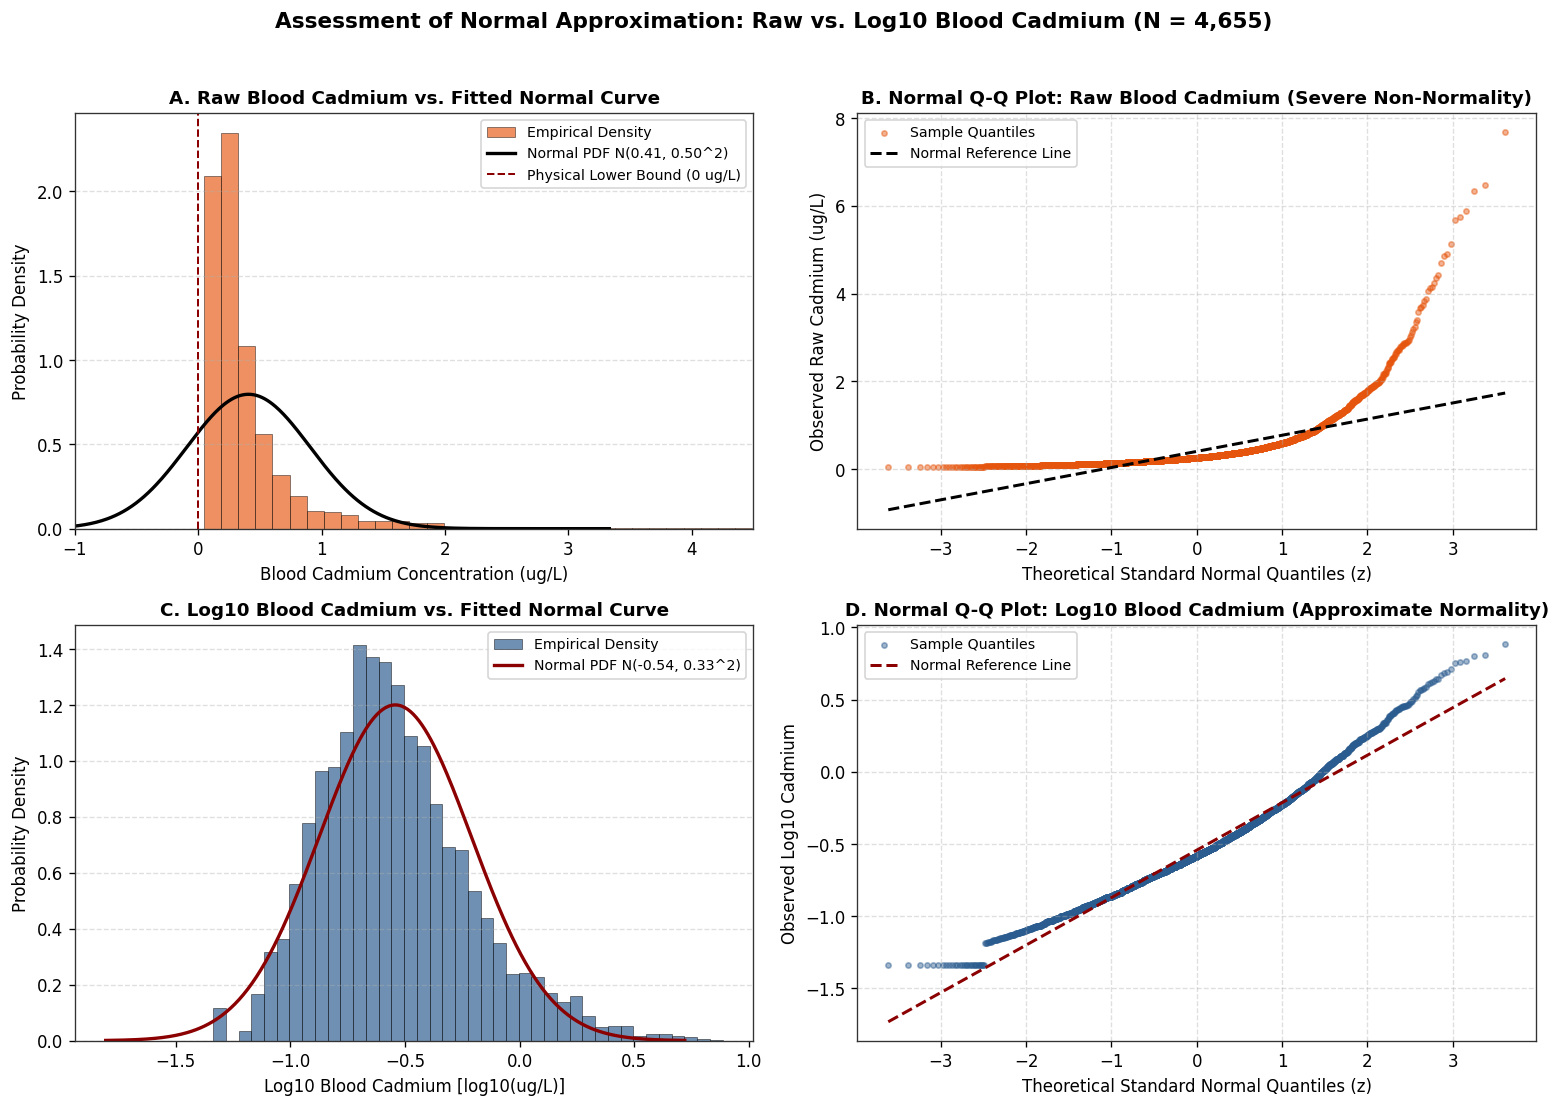

نمودار تسک ۶ ذخیره شد: figures/p2_fig3_normality_cadmium.png


In [8]:
df_norm_shape, df_norm_quantiles = da.evaluate_normal_approximation(df_p2)

print("=== جدول ۶-۱: ارزیابی شکل توزیع، قانون تجربی 68-95-99.7% و احتمال منفی ناممکن ===")
display(df_norm_shape)

print("\n=== جدول ۶-۲: مقایسه صدک‌های تجربی با صدک‌های نظری توزیع نرمال ===")
display(df_norm_quantiles)

fig3_path = da.plot_normality_assessment(df_p2, output_dir="figures")
print("نمودار تسک ۶ ذخیره شد:", fig3_path)

In [9]:
df_ev_table, df_smq710_pmf = da.compute_expectation_and_variance(df_p2)

print("=== جدول ۷-۱: امید ریاضی، واریانس و انحراف معیار متغیرهای تصادفی گسسته و پیوسته ===")
display(df_ev_table)

print("\n=== جدول ۷-۲: توزیع احتمال تجربی دقیق برای متغیر گسسته تعداد روز مصرف سیگار (SMQ710) ===")
display(df_smq710_pmf)

=== جدول ۷-۱: امید ریاضی، واریانس و انحراف معیار متغیرهای تصادفی گسسته و پیوسته ===


,RV_Name,Type,Valid_N,E[X] (Mean),Var_Empirical E[(X-mu)^2],Var_Sample (N-1),SD(X)
0,X_B: High Cadmium Indicator (Discrete Bernoulli),"Discrete {0, 1}",4655,0.2086,0.1651,0.1651,0.4063
1,X_C: Active Nicotine Indicator (Discrete Berno...,"Discrete {0, 1}",4655,0.1959,0.1575,0.1576,0.3969
2,D_cig: Smoking Days in Last 5d (Active Smokers),Discrete {1..5},633,4.5103,1.1504,1.1522,1.0726
3,K_30: High-Cadmium Count in n=30 (Binomial Model),Discrete {0..30},4655,6.2578,4.9525,NaN,2.2254
4,W: Raw Blood Cadmium (ug/L),Continuous,4655,0.4076,0.2504,0.2505,0.5004
5,Y1: Log10 Blood Cadmium [log10(ug/L)],Continuous,4655,-0.5424,0.1105,0.1105,0.3324
6,Y2: Log10 Serum Cotinine [log10(ng/mL)],Continuous,4655,-0.9899,2.7952,2.7958,1.6719
7,Y3: Blood Hemoglobin (g/dL),Continuous,4638,13.9092,2.1033,2.1037,1.4503



=== جدول ۷-۲: توزیع احتمال تجربی دقیق برای متغیر گسسته تعداد روز مصرف سیگار (SMQ710) ===


,x (Smoking Days in Last 5d),Frequency (n),Empirical_Prob p(x),x * p(x),(x - E[X])^2 * p(x)
0,1,24,0.0379,0.0379,0.4672
1,2,36,0.0569,0.1137,0.3584
2,3,33,0.0521,0.1564,0.1189
3,4,40,0.0632,0.2528,0.0165
4,5,500,0.7899,3.9494,0.1894


=== جدول ۸-۱: کوواریانس تجربی، سهم ربع‌های مثبت/منفی و جهت رابطه ===


,Variable_Pair,Valid_N,Mean_X,Mean_Y,Cov_Empirical E[(X-mx)(Y-my)],Cov_Sample (N-1),Q1+Q3_Positive_Share (%),Q2+Q4_Negative_Share (%),Direction
0,Pair 1: Log10 Cotinine (Y2) & Log10 Cadmium (Y1),4655,-0.9899,-0.5424,0.2769,0.2769,64.64,35.36,Positive (Direct)
1,Pair 2: Age in Years (RIDAGEYR) & Log10 Cadmiu...,4655,54.1334,-0.5424,1.3916,1.3919,59.36,40.64,Positive (Direct)
2,Pair 3: Income-to-Poverty (INDFMPIR) & Log10 C...,4103,3.0711,-0.5376,-0.1076,-0.1076,43.99,56.01,Negative (Inverse)


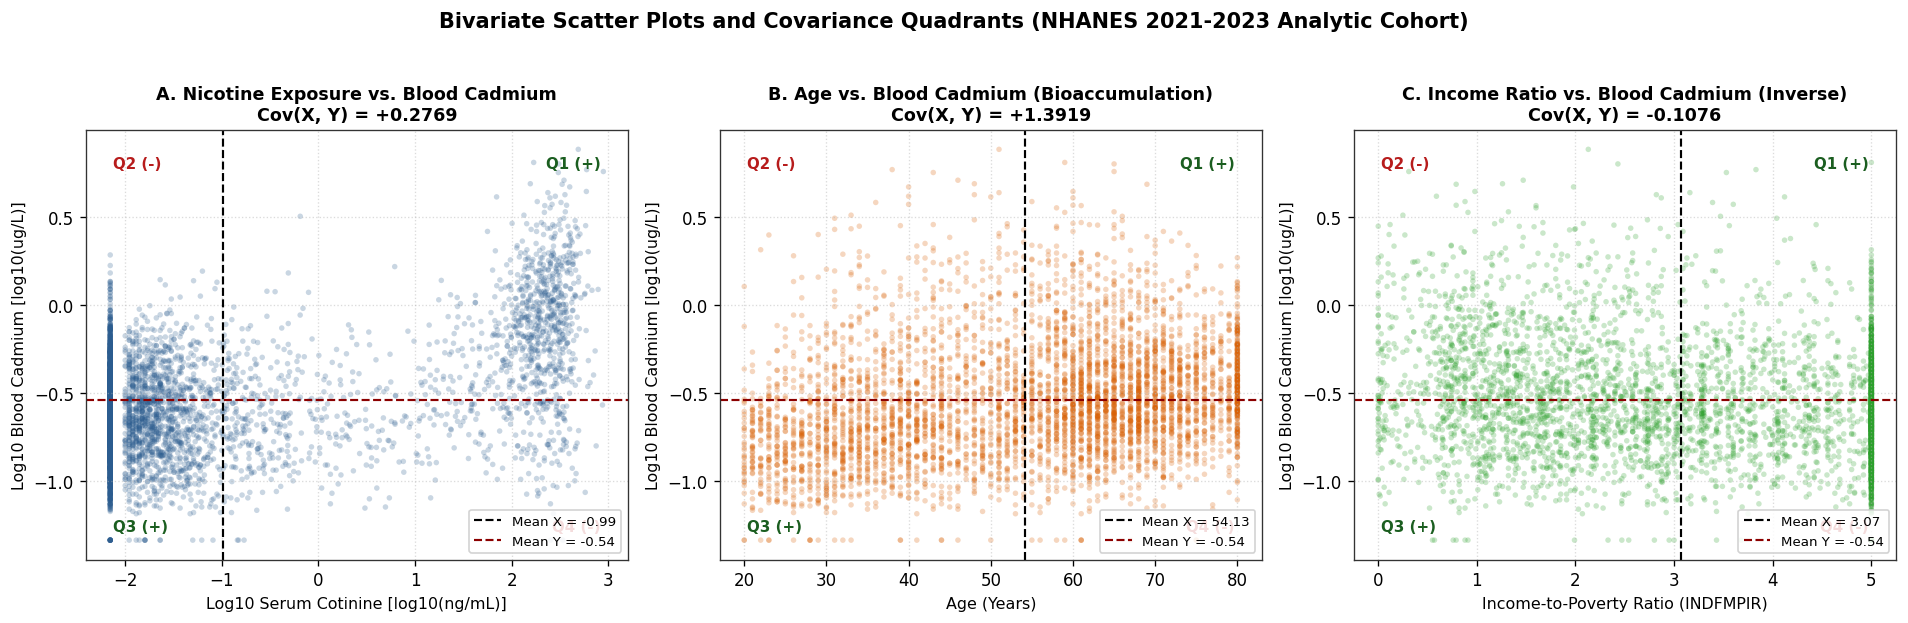

نمودار تسک ۸ ذخیره شد: figures/p2_fig4_bivariate_covariance.png


In [10]:
df_cov_table = da.compute_bivariate_covariance(df_p2)

print("=== جدول ۸-۱: کوواریانس تجربی، سهم ربع‌های مثبت/منفی و جهت رابطه ===")
display(df_cov_table)

fig4_path = da.plot_bivariate_covariance(df_p2, output_dir="figures")
print("نمودار تسک ۸ ذخیره شد:", fig4_path)

In [11]:
import importlib
import src.bayes_and_nhanes_probs as bnp
importlib.reload(bnp)

df_bayes_b, df_bayes_c_lowcd, df_bayes_binary = bnp.compute_bayes_updating(df_p2)

print("=== جدول ۹-۱: به‌روزرسانی بیزی چهار گروه مصرف به شرط کادمیوم بالا P(G_i | B) ===")
display(df_bayes_b)

print("\n=== جدول ۹-۲: به‌روزرسانی بیزی چهار گروه به شرط نیکوتین فعال و کادمیوم پایین P(G_i | C ∩ B^c) ===")
display(df_bayes_c_lowcd)

print("\n=== جدول ۹-۳: به‌روزرسانی بیزی دودویی برای سیگار احتراقی P(A | B) و قانون احتمال کل ===")
display(df_bayes_binary)

=== جدول ۹-۱: به‌روزرسانی بیزی چهار گروه مصرف به شرط کادمیوم بالا P(G_i | B) ===


,Evidence,Group (Hypothesis G_i),Group_N,Prior P(G_i),Likelihood P(E | G_i),Joint P(G_i n E),Total_Prob P(E),Posterior P(G_i | E),Update_Factor (Post/Prior)
0,B: High Cadmium (>=0.5),1. Non-Smoker,3734,0.8021,0.1127,0.0904,0.2086,0.4336,0.54
1,B: High Cadmium (>=0.5),2. Exclusive Vape,146,0.0314,0.0959,0.0030,0.2086,0.0144,0.46
2,B: High Cadmium (>=0.5),3. Exclusive Cigarette,672,0.1444,0.7262,0.1048,0.2086,0.5026,3.48
3,B: High Cadmium (>=0.5),4. Dual User,103,0.0221,0.4660,0.0103,0.2086,0.0494,2.23



=== جدول ۹-۲: به‌روزرسانی بیزی چهار گروه به شرط نیکوتین فعال و کادمیوم پایین P(G_i | C ∩ B^c) ===


,Evidence,Group (Hypothesis G_i),Group_N,Prior P(G_i),Likelihood P(E | G_i),Joint P(G_i n E),Total_Prob P(E),Posterior P(G_i | E),Update_Factor (Post/Prior)
0,C n B^c: Active Nicotine & Low Cd,1. Non-Smoker,3734,0.8021,0.0142,0.0114,0.0739,0.1541,0.19
1,C n B^c: Active Nicotine & Low Cd,2. Exclusive Vape,146,0.0314,0.6986,0.0219,0.0739,0.2965,9.45
2,C n B^c: Active Nicotine & Low Cd,3. Exclusive Cigarette,672,0.1444,0.2098,0.0303,0.0739,0.4099,2.84
3,C n B^c: Active Nicotine & Low Cd,4. Dual User,103,0.0221,0.4660,0.0103,0.0739,0.1395,6.31



=== جدول ۹-۳: به‌روزرسانی بیزی دودویی برای سیگار احتراقی P(A | B) و قانون احتمال کل ===


,Hypothesis,Prior,Likelihood P(B | H),Joint P(H n B),P(B) Law of Total Prob,Posterior P(H | B),Update_Factor
0,A: Combustible Smoker (G3 U G4),0.1665,0.6916,0.1151,0.2086,0.552,3.32
1,A^c: Non-Combustible (G1 U G2),0.8335,0.1121,0.0934,0.2086,0.448,0.54


=== جدول ۱۰-۱ (الف-۱): احتمال شرطی کادمیوم بالا در زیرگروه‌های سنی ===


,Age_Group,Subgroup_N,HighCd_Count,P(B | Subgroup),P(B | Subgroup) %,Diff_vs_Overall_P(B),Smoker_Share_P(A|Sub) %
0,1. Young Adult (20-39),1154,128,0.1109,11.09,-0.0977,16.98
1,2. Middle-Aged (40-59),1323,328,0.2479,24.79,0.0393,21.84
2,3. Older Adult (60+),2178,515,0.2365,23.65,0.0279,13.31



=== جدول ۱۰-۲ (الف-۱): احتمال شرطی کادمیوم بالا بر حسب جنسیت ===


,Gender_Label,Subgroup_N,HighCd_Count,P(B | Subgroup),P(B | Subgroup) %,Diff_vs_Overall_P(B),Smoker_Share_P(A|Sub) %
0,Female,2561,607,0.2370,23.70,0.0284,13.94
1,Male,2094,364,0.1738,17.38,-0.0348,19.96



=== جدول ۱۰-۳ (الف-۱): احتمال شرطی کادمیوم بالا در تقاطع سن × جنس ===


,Age_Group,Gender_Label,Subgroup_N,HighCd_Count,P(B | Subgroup),P(B | Subgroup) %,Diff_vs_Overall_P(B),Smoker_Share_P(A|Sub) %
0,1. Young Adult (20-39),Female,649,81,0.1248,12.48,-0.0838,12.94
1,1. Young Adult (20-39),Male,505,47,0.0931,9.31,-0.1155,22.18
2,2. Middle-Aged (40-59),Female,742,210,0.2830,28.30,0.0744,18.46
3,2. Middle-Aged (40-59),Male,581,118,0.2031,20.31,-0.0055,26.16
4,3. Older Adult (60+),Female,1170,316,0.2701,27.01,0.0615,11.62
5,3. Older Adult (60+),Male,1008,199,0.1974,19.74,-0.0112,15.28


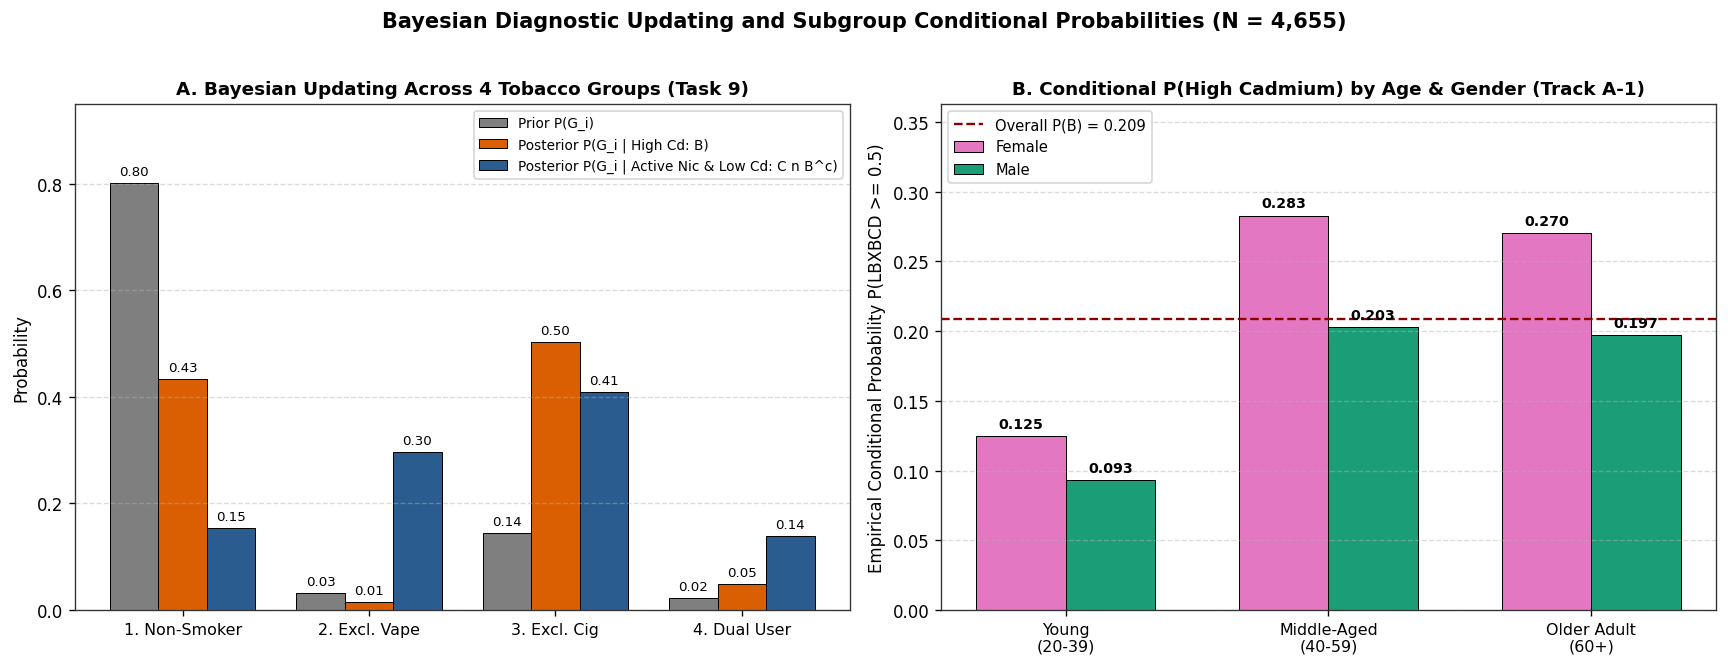

نمودار تسک ۹ و الف-۱ ذخیره شد: figures/p2_fig5_bayes_and_subgroups.png


In [12]:
df_sub_age, df_sub_gender, df_sub_age_gender = bnp.compute_subgroup_conditional_probs(df_p2)

print("=== جدول ۱۰-۱ (الف-۱): احتمال شرطی کادمیوم بالا در زیرگروه‌های سنی ===")
display(df_sub_age)

print("\n=== جدول ۱۰-۲ (الف-۱): احتمال شرطی کادمیوم بالا بر حسب جنسیت ===")
display(df_sub_gender)

print("\n=== جدول ۱۰-۳ (الف-۱): احتمال شرطی کادمیوم بالا در تقاطع سن × جنس ===")
display(df_sub_age_gender)

fig5_path = bnp.plot_bayes_and_subgroups(
    df_p2, df_bayes_b, df_bayes_c_lowcd, df_sub_age_gender, output_dir="figures"
)
print("نمودار تسک ۹ و الف-۱ ذخیره شد:", fig5_path)

=== جدول ۱۱-۱ (الف-۲): مقایسه میانگین و واریانس شمارش در ۱۵۵ زیرنمونه مجزای ۳۰ نفری با Binomial(30, p) ===


,Distribution,Num_Subsamples (M),Mean,Variance,SD,Dispersion_Ratio (Var / Theo_Var),Min,Median,Max
0,"Theoretical Binomial(n=30, p=0.2086)",155,6.258,4.952,2.225,1.00,0,6.0,30
1,"Empirical: Random Disjoint Subsamples (n=30, s...",155,6.258,4.751,2.180,0.96,2,6.0,15
2,Empirical: PSU-Ordered Disjoint Subsamples (n=30),155,6.265,5.741,2.396,1.16,1,6.0,15



=== جدول ۱۱-۲ (الف-۲): مقایسه فراوانی تجربی و مورد انتظار دوجمله‌ای در بازه‌های شمارش k ===


,Count_Bin (k in n=30),Binomial_Theo_Prob,Expected_Subsamples (of 155),Obs_Random_Count,Obs_Random_Prob,Obs_PSU_Count,Obs_PSU_Prob
0,0-3,0.1016,15.7,14,0.0903,15,0.0968
1,4-5,0.2807,43.5,45,0.2903,45,0.2903
2,6-7,0.3393,52.6,58,0.3742,56,0.3613
3,8-9,0.2007,31.1,24,0.1548,25,0.1613
4,10+,0.0777,12.0,14,0.0903,14,0.0903


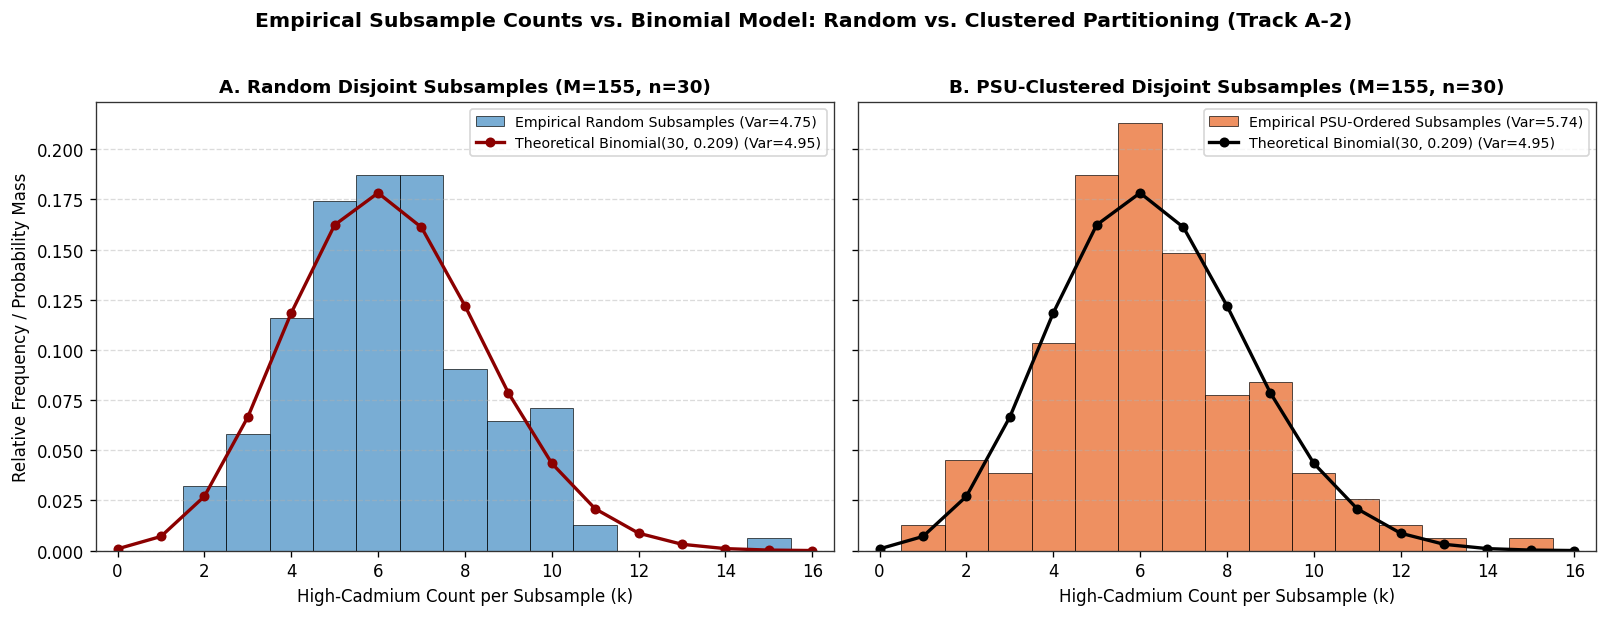

نمودار الزام الف-۲ ذخیره شد: figures/p2_fig6_binomial_subsamples.png


In [13]:
df_sub_summary, df_pmf_comp, raw_sub_arrays = bnp.compare_subsamples_with_binomial(
    df_p2, n_sub=30, seed=42
)

print("=== جدول ۱۱-۱ (الف-۲): مقایسه میانگین و واریانس شمارش در ۱۵۵ زیرنمونه مجزای ۳۰ نفری با Binomial(30, p) ===")
display(df_sub_summary)

print("\n=== جدول ۱۱-۲ (الف-۲): مقایسه فراوانی تجربی و مورد انتظار دوجمله‌ای در بازه‌های شمارش k ===")
display(df_pmf_comp)

fig6_path = bnp.plot_binomial_subsamples(raw_sub_arrays, n_sub=30, output_dir="figures")
print("نمودار الزام الف-۲ ذخیره شد:", fig6_path)

=== جدول ۱۲-۱ (الف-۳): پروفایل چولگی، کشیدگی، نقاط پرت توکی و قانون تجربی هموگلوبین (LBXHGB) ===


,Group,Valid_N,Mean,Median,SD,Q1,Q3,IQR,Skewness,Excess_Kurtosis,Within_1SD (%),Within_2SD (%),Within_3SD (%),Lower_Fence,Upper_Fence,Low_Outliers (n),High_Outliers (n),Total_Outliers (%),Extreme_Low_3IQR (n)
0,Overall Analytic Cohort,4638,13.909,13.9,1.450,13.0,14.9,1.9,-0.329,0.807,69.84,95.45,99.31,10.15,17.75,53,12,1.40,3
1,Female Only,2555,13.245,13.3,1.201,12.5,14.0,1.5,-0.683,1.604,72.60,95.23,98.90,10.25,16.25,45,8,2.07,2
2,Male Only,2083,14.723,14.8,1.308,14.0,15.5,1.5,-0.725,2.140,72.35,94.38,99.23,11.75,17.75,58,12,3.36,5



=== جدول ۱۲-۲ (الف-۳): مقایسه صدک‌های تجربی هموگلوبین با صدک‌های نظری توزیع نرمال ===


,Percentile,Empirical_LBXHGB (g/dL),Normal_Theoretical (g/dL),Diff (Emp - Theo)
0,P1,10.0,10.535,-0.535
1,P5,11.5,11.524,-0.024
2,P25,13.0,12.931,0.069
3,P50,13.9,13.909,-0.009
4,P75,14.9,14.888,0.012
5,P95,16.2,16.295,-0.095
6,P99,17.2,17.283,-0.083


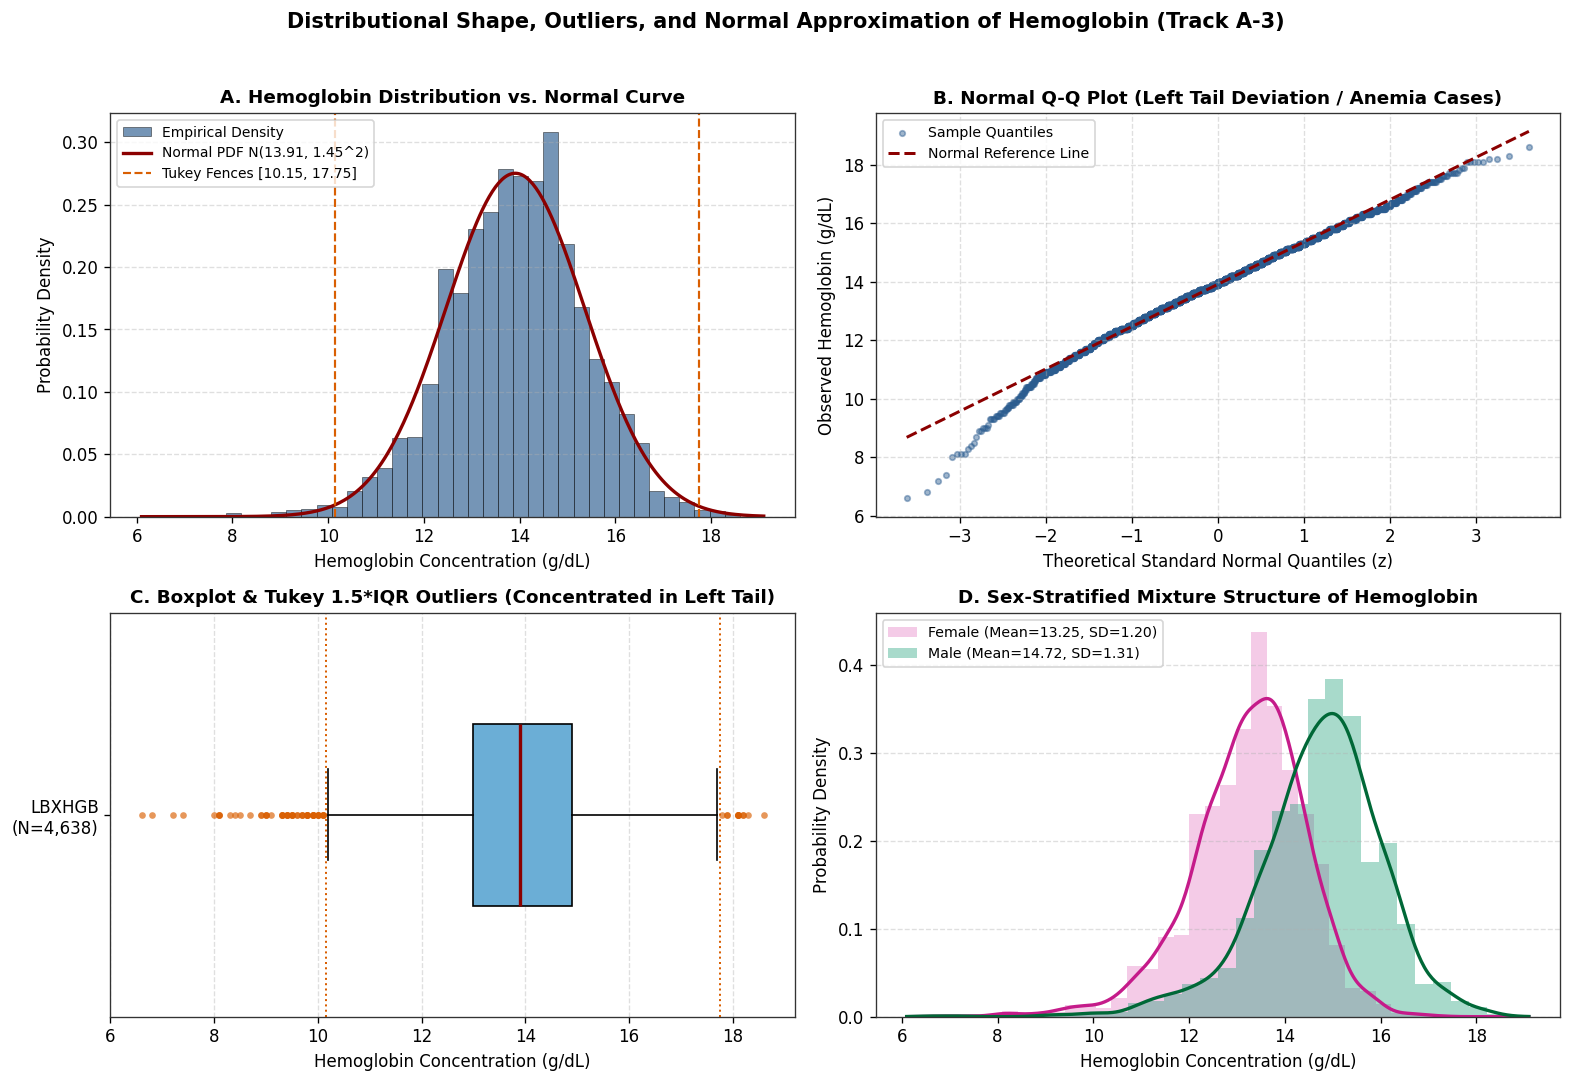

نمودار الزام الف-۳ ذخیره شد: figures/p2_fig7_hemoglobin_shape.png


In [14]:
df_hgb_profile, df_hgb_quantiles = bnp.analyze_health_biomarker_shape(df_p2)

print("=== جدول ۱۲-۱ (الف-۳): پروفایل چولگی، کشیدگی، نقاط پرت توکی و قانون تجربی هموگلوبین (LBXHGB) ===")
display(df_hgb_profile)

print("\n=== جدول ۱۲-۲ (الف-۳): مقایسه صدک‌های تجربی هموگلوبین با صدک‌های نظری توزیع نرمال ===")
display(df_hgb_quantiles)

fig7_path = bnp.plot_hemoglobin_shape(df_p2, output_dir="figures")
print("نمودار الزام الف-۳ ذخیره شد:", fig7_path)

In [15]:
df_w_marg, df_w_cond = bnp.compare_unweighted_vs_weighted_probabilities(df_p2)

print("=== جدول ۱۳-۱ (الف-۴): مقایسه فراوانی نسبی خام نمونه با برآورد احتمال جمعیت (WTPH2YR) ===")
display(df_w_marg)

print("\n=== جدول ۱۳-۲ (الف-۴): مقایسه احتمال شرطی خام و وزن‌دار P(B | G_i) در چهار گروه ===")
display(df_w_cond)

=== جدول ۱۳-۱ (الف-۴): مقایسه فراوانی نسبی خام نمونه با برآورد احتمال جمعیت (WTPH2YR) ===


,Event,Sample_Count (n),Unweighted_Prob (Sample Freq),Weighted_Prob (Pop Estimate),Diff (W - Unw),Relative_Change (%)
0,B: High Blood Cadmium (LBXBCD >= 0.5 ug/L),971,0.2086,0.1856,-0.0230,-11.02
1,A: Combustible Smoker (G3 U G4),775,0.1665,0.1672,0.0007,0.43
2,C: Active Nicotine (LBXCOT >= 10.0 ng/mL),912,0.1959,0.2014,0.0055,2.79
3,G2: Exclusive Vape User,146,0.0314,0.0386,0.0073,23.19
4,Older Adult (Age >= 60 Years - Design Driver),2178,0.4679,0.3182,-0.1497,-31.99



=== جدول ۱۳-۲ (الف-۴): مقایسه احتمال شرطی خام و وزن‌دار P(B | G_i) در چهار گروه ===


,Smoking_Group,Group_N,Unweighted P(B | G_i),Weighted P_w(B | G_i),Diff (W - Unw),Relative_Change (%)
0,1. Non-Smoker,3734,0.1127,0.0941,-0.0186,-16.54
1,2. Exclusive Vape,146,0.0959,0.0727,-0.0232,-24.15
2,3. Exclusive Cigarette,672,0.7262,0.6990,-0.0272,-3.75
3,4. Dual User,103,0.4660,0.3759,-0.0901,-19.33
